### 1. Importing libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, silhouette_score
from sklearn.model_selection import train_test_split, GridSearchCV
import warnings
warnings.filterwarnings('ignore')

### 2. Reading File

In [7]:
df = pd.read_csv('/content/cleaned_data.csv')

### 3. Data segmentation and standardization

In [8]:
df_clean = df.drop_duplicates().copy()

selected_cols = [
        'RIDAGEYR', 'RIAGENDR', 'BMXHT',
        'BMXWT', 'BMXBMI',
        'SLD010H', 'physically_active',
        'smoking_status', 'alcohol_use'
    ]

X = df_clean[selected_cols]
Y = df_clean['diabetes']

x_train, x_test, y_train, y_test = train_test_split(X, Y, random_state=119, test_size=0.25, stratify=Y)

standard_scale = StandardScaler()
x_train_scaled = standard_scale.fit_transform(x_train)
x_test_scaled = standard_scale.transform(x_test)

### 4. Creating an initial model with default parameters

In [9]:
def basic_model(model):
    model = model
    model_fit = model.fit(x_train_scaled, y_train)
    model_pred = model_fit.predict(x_test_scaled)
    return f"""for {model}:
Classification Report:\n{classification_report(y_test, model_pred)}\n
"""
print(basic_model(LogisticRegression()))
print(basic_model(SVC()))
print(basic_model(DecisionTreeClassifier()))
print(basic_model(RandomForestClassifier()))
print(basic_model(GradientBoostingClassifier()))
print(basic_model(KNeighborsClassifier()))

for LogisticRegression():
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      2296
           1       0.35      0.04      0.07       182

    accuracy                           0.92      2478
   macro avg       0.64      0.52      0.51      2478
weighted avg       0.89      0.92      0.90      2478



for SVC():
Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      2296
           1       0.00      0.00      0.00       182

    accuracy                           0.93      2478
   macro avg       0.46      0.50      0.48      2478
weighted avg       0.86      0.93      0.89      2478



for DecisionTreeClassifier():
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      2296
           1       0.25      0.27      0.26       182

    accuracy                           0.8

### 5. Creating custom parameters for evaluating and comparing model performance

In [10]:
log_param_grid = {
    'penalty': ['l1', 'l2', 'elasticnet', None],
    'solver': ['lbfgs', 'liblinear', 'sag', 'saga']
}

svc_param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'degree': [2, 3, 4, 5]
}

decision_param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [7, 9],
    'min_samples_split': [4, 6],
}

random_param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [3, 5, 7, 9],
    'min_samples_split': [2, 4, 6, 8],
}

gradiant_param_grid = {
    'loss': ['log_loss', 'deviance', 'exponential'],
    'learning_rate': [0.2, 0.4, 0.6],
    'n_estimators': [50, 100, 150],
}

knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'] ,
    'algorithm': ['auto', 'kd_tree', 'brute'],
}

### 6. Implementing Models for Performance Comparison

In [11]:

models = [
    LogisticRegression(max_iter=1000, random_state=119),
    SVC(random_state=119),
    DecisionTreeClassifier(random_state=119),
    RandomForestClassifier(random_state=119),
    GradientBoostingClassifier(random_state=119),
    KNeighborsClassifier()
]

param_grids = [
    log_param_grid,
    svc_param_grid,
    decision_param_grid,
    random_param_grid,
    gradiant_param_grid,
    knn_param_grid
]

li = []

for model, param_grid in zip(models, param_grids):
    grid = GridSearchCV(
                estimator=model,
                param_grid=param_grid,
                verbose=1,
                scoring='roc_auc',
                cv=3
            )
    grid.fit(x_train_scaled, y_train)

    grid_pred = grid.predict(x_test_scaled)

    results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
    li.append(results)

    print(f"""for {model}:
        Classification Report:\n{classification_report(y_test, grid_pred)}\n
        Best Params: {grid.best_params_}\n""")

print(li)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
for LogisticRegression(max_iter=1000, random_state=119):
        Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      2296
           1       0.37      0.04      0.07       182

    accuracy                           0.92      2478
   macro avg       0.65      0.52      0.52      2478
weighted avg       0.89      0.92      0.90      2478


        Best Params: {'penalty': 'l2', 'solver': 'liblinear'}

Fitting 3 folds for each of 16 candidates, totalling 48 fits
for SVC(random_state=119):
        Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      2296
           1       0.00      0.00      0.00       182

    accuracy                           0.93      2478
   macro avg       0.46      0.50      0.48      2478
weighted avg       0.86      0.93      0.89      2478


        Best 

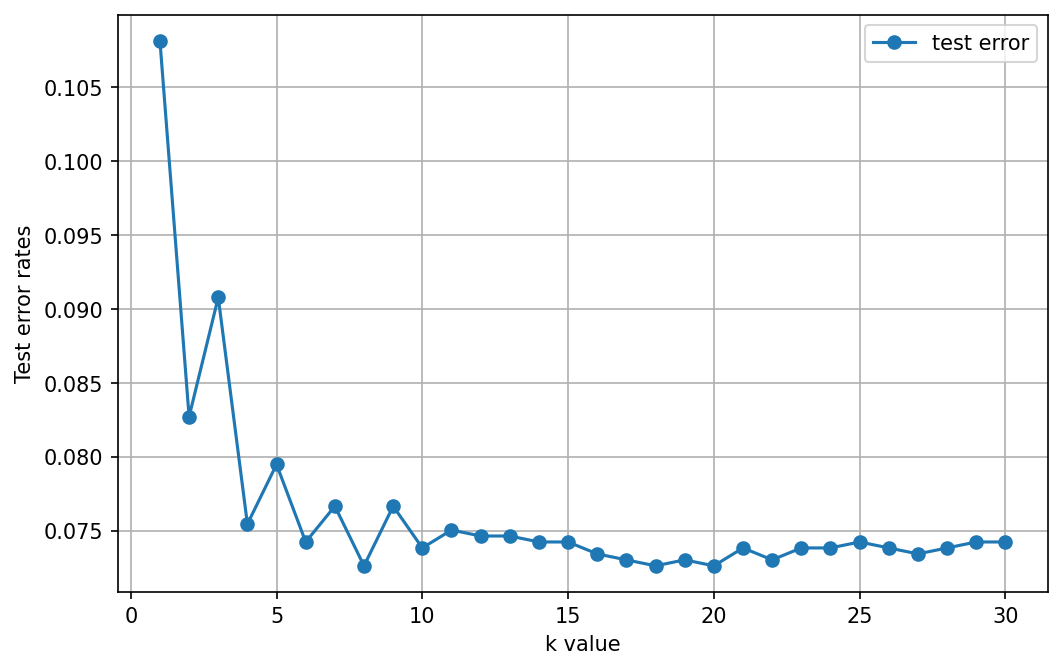

In [12]:
test_error_rates = []
for k in range(1,31):
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(x_train_scaled, y_train)
    y_pred_test = knn_model.predict(x_test_scaled)

    test_error = 1 - accuracy_score(y_test, y_pred_test)
    test_error_rates.append(test_error)

plt.figure(figsize=(8, 5), dpi=150)
plt.plot(range(1,31), test_error_rates, marker="o", label = 'test error')
plt.legend()
plt.ylabel("Test error rates")
plt.xlabel("k value")
plt.grid()
plt.show()

### 8. Saving the best model

In [13]:
best_model = grid.best_estimator_
print(best_model)

KNeighborsClassifier(algorithm='brute', n_neighbors=9, weights='distance')


In [14]:
y_test_pred = best_model.predict(x_test_scaled)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))



Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      2296
           1       0.42      0.09      0.15       182

    accuracy                           0.92      2478
   macro avg       0.68      0.54      0.56      2478
weighted avg       0.90      0.92      0.90      2478



In [15]:
correlations = df.corrwith(Y).abs().sort_values(ascending=False)
print("Top 15 features correlated with Target:")
print(correlations.head(15))

Top 15 features correlated with Target:
diabetes          1.000000
LBXGH             0.546634
RIDAGEYR          0.341905
DIQ170            0.337109
any_medication    0.315445
RXDUSE            0.302371
DMDEDUC2          0.262633
DMDHRAGE          0.260332
DMDHHSZE          0.256550
DMDMARTL          0.241051
BMXBMI            0.231768
BMXWT             0.230799
SIAPROXY          0.198629
MCQ160A           0.183029
DMDHHSIZ          0.151798
dtype: float64


In [16]:
import joblib

best_model = grid.best_estimator_
results = grid.cv_results_

joblib.dump(best_model, "best_diabetes_model.pkl")
joblib.dump(standard_scale, "scaler.pkl")

results = pd.DataFrame(results).sort_values("rank_test_score")
results.to_csv("grid_search_results.csv", index=False)
results.to_pickle("grid_search_results.pkl")